# Data Access: How To Query The ESA MAAP Catalog Via API

The script below shows how to use the STAC API to query the ESA MAAP catalog. With the SATC API, you can stream, preview, or download data.

### 1. Packages and Libraries

In [2]:
%pip install aiohttp requests

from shapely.geometry import Polygon
from rasterio.windows import Window
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from pystac_client import Client
from folium import GeoJson
import geopandas as gpd
from io import BytesIO
import rasterio as rio
from tqdm import tqdm
from PIL import Image
import pandas as pd
import numpy as np
import requests
import pathlib
import fsspec
import folium
import fiona
import os

fiona.supported_drivers["KML"] = "rw"  # Enable kml driver

Note: you may need to restart the kernel to use updated packages.


### 2. Query the ESA MAAP STAC catalog

In [2]:
catalog_url = 'https://catalog.maap.eo.esa.int/catalogue/'
catalog = Client.open(catalog_url)

#### 2.1. Find the collection

In [3]:
# find all Biomass collections
results = catalog.collection_search(
    filter="platform='Biomass'",
    datetime="2025-12-01T00:00:00.000Z/..",
)
print(f"{results.matched()} collections found.")

data = results.collection_list_as_dict()
df = pd.json_normalize(data, record_path=["collections"]).sort_values(
    by="title", ignore_index=True
)
df[["id", "title", "extent.temporal.interval"]]

17 collections found.


,id,title,extent.temporal.interval
0,BiomassAux,Biomass Auxiliary,"[[2024-07-31T00:00:00.000Z, None]]"
1,BiomassAuxIOC,Biomass Auxiliary (IOC),"[[2024-07-31T00:00:00.000Z, None]]"
2,BiomassAuxRest,Biomass Auxiliary Restricted,"[[2024-07-31T00:00:00.000Z, None]]"
3,BiomassCalVal10,Biomass Cal/Val,"[[2025-04-29T00:00:00.000Z, None]]"
4,BiomassLevel0,Biomass Level 0,"[[2024-07-31T00:00:00.000Z, None]]"
5,BiomassLevel0IOC,Biomass Level 0 (IOC),"[[2024-07-31T00:00:00.000Z, None]]"
6,BiomassLevel1a,Biomass Level 1A,"[[2025-11-21T00:00:00.000Z, None]]"
7,BiomassLevel1aIOC,Biomass Level 1A (IOC),"[[2024-07-31T00:00:00.000Z, None]]"
8,BiomassLevel1b,Biomass Level 1B,"[[2024-07-31T00:00:00.000Z, None]]"
9,BiomassLevel1bIOC,Biomass Level 1B (IOC),"[[2024-07-31T00:00:00.000Z, None]]"


#### 2.2. Select a collection and narrow down the search

You can exploit several filter parameters to narrow down your research. All the available queriables you can use to filter a prodict are reported here:
- [Queryables for L1a products](https://catalog.maap.eo.esa.int/catalogue/collections/BiomassLevel1a/queryables)
- [Queryables for L1b products](https://catalog.maap.eo.esa.int/catalogue/collections/BiomassLevel1b/queryables)
- [Queryables for L1c products](https://catalog.maap.eo.esa.int/catalogue/collections/BiomassLevel1c/queryables)


**In general, you can search for any collection you want:**

https\://catalog.maap.eo.esa.int/catalogue/collections/**name_of_the_collection**/queryables

In [1]:
search_l2b = catalog.search(
    collections=["BiomassLevel2a"],
    filter="product:type='FP_FH__L2B'",
    bbox=STUDY_BBOX,
    max_items=100,
    method="GET"
)

l2b_items = list(search_l2b.items())

print("Available Level-2B products:", len(l2b_items))

for item in l2b_items:
    print(item.id)

NameError: name 'catalog' is not defined

**You can learn more about the different processing levels for each available Mission here:**
https://earth.esa.int/eogateway/search?category=missions

#### 2.3. Visualise the returned IDs into MAP

In [5]:
features = []
for it in items:
    if it.geometry is None:
        raise ValueError(f"Item {it.id} has no geometry (footprint).")
    props = it.properties or {}
    features.append({
        "type": "Feature",
        "geometry": it.geometry,
        "properties": {
            "product_id": it.id,
            "start_datetime": props.get("start_datetime"),
            "end_datetime": props.get("end_datetime"),
        },
    })


gdf = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")
gdf = gdf.reset_index()
gdf = gdf[["index", "product_id", "start_datetime", "end_datetime", "geometry"]]
gdf.head(len(items))

,index,product_id,start_datetime,end_datetime,geometry
0,0,BIO_S1_SCS__1S_20260210T204019_20260210T204039...,2026-02-10T20:40:19.604Z,2026-02-10T20:40:39.997Z,"POLYGON ((-39.56829 -12.13486, -39.00251 -12.2..."
1,1,BIO_S1_SCS__1S_20260210T204116_20260210T204137...,2026-02-10T20:41:16.630Z,2026-02-10T20:41:37.027Z,"POLYGON ((-40.28854 -15.60275, -39.7138 -15.71..."
2,2,BIO_S1_SCS__1S_20260210T204057_20260210T204118...,2026-02-10T20:40:57.621Z,2026-02-10T20:41:18.017Z,"POLYGON ((-40.04974 -14.44666, -39.47566 -14.5..."
3,3,BIO_S1_SCS__1S_20260210T203941_20260210T204001...,2026-02-10T20:39:41.592Z,2026-02-10T20:40:01.984Z,"POLYGON ((-39.08313 -9.82373, -38.52347 -9.937..."
4,4,BIO_S1_SCS__1S_20260210T221326_20260210T221346...,2026-02-10T22:13:26.534Z,2026-02-10T22:13:46.913Z,"POLYGON ((-60.21453 6.36271, -59.66866 6.24447..."
5,5,BIO_S1_SCS__1S_20260210T221908_20260210T221928...,2026-02-10T22:19:08.559Z,2026-02-10T22:19:28.955Z,"POLYGON ((-64.59839 -14.44587, -64.01868 -14.5..."
6,6,BIO_S1_SCS__1S_20260210T221927_20260210T221947...,2026-02-10T22:19:27.569Z,2026-02-10T22:19:47.966Z,"POLYGON ((-64.83865 -15.6018, -64.25546 -15.71..."
7,7,BIO_S1_SCS__1S_20260210T221830_20260210T221850...,2026-02-10T22:18:30.542Z,2026-02-10T22:18:50.936Z,"POLYGON ((-64.11465 -12.13457, -63.54525 -12.2..."
8,8,BIO_S1_SCS__1S_20260210T222024_20260210T222045...,2026-02-10T22:20:24.604Z,2026-02-10T22:20:45.004Z,"POLYGON ((-65.50786 -19.07893, -64.9178 -19.19..."
9,9,BIO_S1_SCS__1S_20260210T221617_20260210T221637...,2026-02-10T22:16:17.510Z,2026-02-10T22:16:37.896Z,"POLYGON ((-62.43757 -4.03928, -61.88603 -4.154..."


In [6]:
## Ensure both are WGS84 for folium
gdf = gdf.to_crs("EPSG:4326")

# Center/zoom using bounds
bounds = gpd.GeoSeries(list(gdf.geometry), crs="EPSG:4326")
minx, miny, maxx, maxy = bounds.total_bounds
center = [(miny + maxy) / 2, (minx + maxx) / 2]

m = folium.Map(location=center, tiles="OpenStreetMap", zoom_start=3)

def style(_):
    return {"color": "#ff7f0e", "weight": 1, "fillOpacity": 0.10}  

GeoJson(
    gdf.__geo_interface__,
    name=f"Products ({len(gdf)})",
    tooltip=folium.GeoJsonTooltip(fields=["product_id", "index"]),
    style_function=style,
).add_to(m)


folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[miny, minx], [maxy, maxx]])
m

#### 2.4. Choose your product

Each granule includes multiple **assets**, which are different files that serve distinct purposes. These assets can include preview images, scientific data, metadata, and more. Because Biomass products are stored unzipped, you can point to single files instead of downloading the entire archive.

**Examples / Tips**: 

- **Want a quick look?** Use the quicklook or thumbnail to preview the data
- **Need to analyze?** Work with the individual product files enclosure_i_abs_tiff and enclosure_i_phase (.tiff files)
- **Don't need everything?** Avoid the .zip unless you really need to download all files

In [7]:
idx_chosen = 0
biomass_product = items[idx_chosen]

In [8]:
# Inspect results 

print(f"Item ID: {biomass_product.id}")
print(f"  - Datetime: {biomass_product.datetime}")
print(f"  - BBOX: {biomass_product.bbox}")
print(f"  - Properties: {biomass_product.properties}")
print("  - Assets:")
for key, asset in biomass_product.assets.items():
    print(f"      • {key}: {asset.href}")
print()

Item ID: BIO_S1_SCS__1S_20260210T204019_20260210T204039_T_G01_M02_C01_T013_F165_01_DMNMNL
  - Datetime: 2026-02-10 20:40:19.604000+00:00
  - BBOX: [-39.56829, -12.247952, -38.741856, -10.89629]
  - Properties: {'eofeos:repeat_cycle_id': '1', 'start_datetime': '2026-02-10T20:40:19.604Z', 'end_datetime': '2026-02-10T20:40:39.997Z', 'processing:facility': 'Biomass CPF', 'product:type': 'S1_SCS__1S', 'eofeos:global_coverage_id': '1', 'sat:anx_datetime': '2026-02-10T19:48:27.298Z', 'title': 'BIO_S1_SCS__1S_20260210T204019_20260210T204039_T_G01_M02_C01_T013_F165_01_DMNMNL', 'platform': 'Biomass', 'eofeos:major_cycle_id': '2', 'datetime': '2026-02-10T20:40:19.604Z', 'instruments': ['P-SAR'], 'constellation': 'Biomass', 'sat:orbit_state': 'descending', 'storage:schemes': {'biomass-pdgs-01': {'bucket': 'biomass-pdgs-01', 'description': 'This endpoint provides access to EO data which is stored on the object storage of the ESA MAAP. See the [documentation](https://portal.maap.eo.esa.int/dataacces

#### 2.5. Display the quicklook of the data

In [9]:
ql_url = biomass_product.assets['quicklook_jpg'].href
print(f"href of the QL: {ql_url}")

from IPython.display import Image, display
print("\n")
display(Image(url= ql_url))

href of the QL: https://catalog.maap.eo.esa.int/data/biomass-pdgs-01/BiomassLevel1a/2026/02/10/BIO_S1_SCS__1S_20260210T204019_20260210T204039_T_G01_M02_C01_T013_F165_01_DMNMNL/public/BIO_S1_SCS__1S_20260210T204019_20260210T204039_T_G01_M02_C01_T013_F165_01_DMNMNL.BI.JPG




#### 2.6. Stream and plot data

While the discovery of data (querying the ESA MAAP catalogue and display the quicklook) does not require any authentication or authorization, accessing the data requires a token generated with an authorized ESA account (EO Sign in) to verify the user. 

Generate your personal access token [here](https://portal.maap.eo.esa.int/ini/services/auth/token/index.php)

This token is valid for 90 days. It is an offline token that in combination with a set of (permanent) credentials can be used to generate refresh tokens to actually access the data.

In [10]:
# This is permanently valid, you don't need to change the two lines below.
CLIENT_ID="offline-token"
CLIENT_SECRET="p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE"

**You need to create a .txt file and just paste your token inside**

In [11]:
if pathlib.Path("/home/jovyan/token.txt").exists(): # Put here your .txt file path
  with open("token.txt","rt") as f:
    OFFLINE_TOKEN = f.read().strip().replace("\n","")
    url = "https://iam.maap.eo.esa.int/realms/esa-maap/protocol/openid-connect/token"
    data = {
        "client_id": CLIENT_ID,
        "client_secret": CLIENT_SECRET,
        "grant_type": "refresh_token",
        "refresh_token": OFFLINE_TOKEN,
        "scope": "offline_access openid"
    }

    response = requests.post(url, data=data)
    response.raise_for_status()

    response_json = response.json()
    access_token = response_json.get('access_token')
    print("Access token retrieved successfully.")

    if not access_token:
        raise RuntimeError("Failed to retrieve access token from IAM response")

else:
    raise RuntimeError(f"No token file found in {os.getcwd()} !")

Access token retrieved successfully.


**The function below is used to stream the data**

In [12]:
def read_rio_streaming(url, token, subset=False):
    """
    Stream a remote raster file over HTTPS using a bearer token and read
    its band data with rasterio.

    The function:
    - Authenticates using an HTTP Authorization header
    - Opens the raster file directly from a remote stream
    - Reads all raster bands into memory
    - Optionally reads only a specified pixel window (subset)
    - Accesses Ground Control Points (GCP-based georeferencing)

    Parameters
    ----------
    url : str
        HTTPS URL pointing to a raster file (e.g., GeoTIFF).
    token : str
        Bearer token used for HTTP authentication.
    subset : tuple or False, optional
        Optional pixel window defined as
        (col_offset, row_offset, width, height).
        If False, the full raster is read.

    Returns
    -------
    src : rasterio.io.DatasetReader
        Rasterio dataset object (closed after reading).
    bands : list of numpy.ndarray
        List of arrays containing raster band data.
    """

    # Create an authenticated HTTPS filesystem for streaming access
    fs = fsspec.filesystem("https", headers={"Authorization": f"Bearer {token}"})

    # Open the remote raster file as a binary stream
    with fs.open(url, "rb") as f:
        with rio.open(f) as src:
            if subset:
                # Define a pixel window to read only part of the raster
                window = Window(
                    col_off=subset[0],
                    row_off=subset[1],
                    width=subset[2],
                    height=subset[3],
                )

                # Read each band within the specified window
                bands = [src.read(i + 1, window=window) for i in range(src.count)]

                # Retrieve ground control points (GCP-based georeferencing)
                gcps = src.get_gcps()
            else:
                # Read full raster bands into memory
                bands = [src.read(i + 1) for i in range(src.count)]

                # Retrieve ground control points (GCP-based georeferencing)
                gcps = src.get_gcps()

        return src, bands

**Now let's plot the RGP Pauli of the selected image**

In [13]:
abs_img_url = biomass_product.assets['enclosure_i_abs_tiff'].href
phase_img_url = biomass_product.assets['enclosure_i_phase_tiff'].href

src, bands = read_rio_streaming(abs_img_url, access_token, subset=False)
src_phase, phase = read_rio_streaming(phase_img_url, access_token, subset=False)

print(np.shape(bands))

# Magnitude 
HH_abs = bands[0]
HV_abs = bands[1]
VH_abs = bands[2]
VV_abs = bands[3]

# Phase 
HH_phase = phase[0]
HV_phase = phase[1]
VH_phase = phase[2]
VV_phase = phase[3]

# here we combine the abs, and phase values to form a complex number 
HH = HH_abs * np.exp(1j*HH_phase)
HV = HV_abs * np.exp(1j*HV_phase)
VH = VH_abs * np.exp(1j*VH_phase)
VV = VV_abs * np.exp(1j*VV_phase)


(4, 20778, 1328)


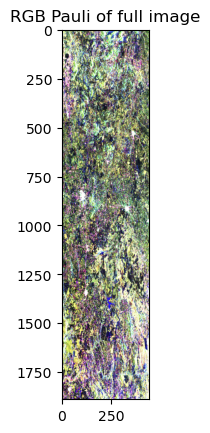

In [14]:
from scipy import signal
win = [11, 3]

kernel  = np.ones((win[0],win[1]),np.float32)/(win[0]*win[1])


k1Full = np.fliplr(np.flipud(HH+VV))
k2Full = np.fliplr(np.flipud(HH-VV))
k3Full = np.fliplr(np.flipud(HV+VH))

da_full = np.shape(HH)[0]  
dr_full = np.shape(HH)[0]
    
# del HHFull, VVFull, VHFull, HVFull

# Now we do average and decimation to get the elmemehts of the Coherency matrix.
# Filtering the images again
T11Full =  signal.convolve2d(np.abs(k1Full)**2, kernel, 
                              mode='same', boundary='fill', fillvalue=0) 
T11 = T11Full[::win[0],::win[1]]

# Now let's get the other diagonal elements
T22Full =  signal.convolve2d(np.abs(k2Full)**2, kernel, 
                              mode='same', boundary='fill', fillvalue=0) 
T22 = T22Full[::win[0],::win[1]]

T33Full =  signal.convolve2d(np.abs(k3Full)**2, kernel, 
                              mode='same', boundary='fill', fillvalue=0) 
T33 = T33Full[::win[0],::win[1]]

# Now let's get the off diagonal elements 
T12Full =  signal.convolve2d(k1Full*np.conj(k2Full), kernel, 
                              mode='same', boundary='fill', fillvalue=0) 
T12 = T12Full[::win[0],::win[1]]

T13Full =  signal.convolve2d(k1Full*np.conj(k3Full), kernel, 
                              mode='same', boundary='fill', fillvalue=0) 
T13 = T13Full[::win[0],::win[1]]

T23Full =  signal.convolve2d(k2Full*np.conj(k3Full), kernel, 
                              mode='same', boundary='fill', fillvalue=0) 
T23 = T23Full[::win[0],::win[1]]

# Once we have all the elements we can visualise the diagonal (powers) in an RGB
size = np.shape(T11)     # this function tell us the size
iRGBPauli = np.zeros([size[0],size[1],3])    # create the 3D container
iRGBPauli[:,:,0] = T22/(T22.mean()*1.5)
iRGBPauli[:,:,1] = T33/(T33.mean()*1.5)
iRGBPauli[:,:,2] = T11/(T11.mean()*1.5)
iRGBPauli[np.abs(iRGBPauli) > 1] = 1

# path_out = str(path_save) + '/RGB_Pauli_full_' + flag_image
fig = plt.figure()      
plt.title("RGB Pauli of full image")
plt.imshow(iRGBPauli)
# fig.savefig(path_out, bbox_inches='tight', pad_inches=0)


#### 2.7. Download Data

You can directly download data from catalog to Coding. First you need to create a .txt file with your token as described above.

**The set of functions below are used to retrieve the token and to download your data**

In [15]:
def get_token():
    """Use OFFLINE_TOKEN to fetch a short-lived access token."""

    if not all([OFFLINE_TOKEN, CLIENT_ID, CLIENT_SECRET]):
        raise ValueError("Missing OFFLINE_TOKEN, CLIENT_ID, or CLIENT_SECRET in credentials file")

    url = "https://iam.maap.eo.esa.int/realms/esa-maap/protocol/openid-connect/token"
    data = {
        "client_id": CLIENT_ID,
        "client_secret": CLIENT_SECRET,
        "grant_type": "refresh_token",
        "refresh_token": OFFLINE_TOKEN,
        "scope": "offline_access openid"
    }

    response = requests.post(url, data=data)
    response.raise_for_status()

    response_json = response.json()
    access_token = response_json.get('access_token')

    if not access_token:
        raise RuntimeError("Failed to retrieve access token from IAM response")

    return access_token



def download_product(product_url: str, output_filename: str):
    """Download a file from a URL using a refresh access token."""
    print("Requesting access token...")
    token = get_token()
    headers = {"Authorization": f"Bearer {token}"}

    print(f"Downloading product:\n  {product_url}")
    with requests.get(product_url, headers=headers, stream=True) as r:
        r.raise_for_status()
        with open(output_filename, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)
    print(f"Download complete: {output_filename}")

**Example with the .zip product:**

In [17]:
product_url = (
    biomass_product.assets['product'].href
)

output_file = "bio_prod.zip"   # Substitute with the desired output file name (make sure to include the file extension)
download_product(product_url, output_file)

Requesting access token...
  https://catalog.maap.eo.esa.int/data/zipper/biomass-pdgs-01/BiomassLevel1a/2026/02/10/BIO_S1_SCS__1S_20260210T204019_20260210T204039_T_G01_M02_C01_T013_F165_01_DMNMNL/BIO_S1_SCS__1S_20260210T204019_20260210T204039_T_G01_M02_C01_T013_F165_01_DMNMNL
Download complete: bio_prod.zip
